# Tests and Plots

## Imports and functions

In [38]:
from random import randint,random

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
import emcee

from benchmark_distr import sample_funnel, log_neal_funnel, log_gaussian
from HamiltonianSampler import leapfrog_d,alpha_d, gaussian_ND

In [39]:
rng = np.random.default_rng(42)

In [40]:
sigma = 130
means = [60,30]
Sigma = np.array([[sigma,0],
         [0,sigma]])
ts = np.linspace(0,100,100)

def dchain(x_0,N,dt,L,mass_matrix,method = "gaussian"):
    if method == "gaussian":
        print("Gaussian sampling")
        logp = lambda x: np.log(gaussian_ND(x,means,Sigma))
    elif method == "neal":
        print("Neal's funnel sampling")
        logp = log_neal_funnel
        is_log = True
    else:
        print("invalid method")
        return "err"
    #needs x_0 in shape (N_chains,d)
    X = np.zeros((N,len(x_0),len(x_0[0])))
    X[0] = x_0
    print(x_0.shape)
    for n in range(N-1):
        p_0 = np.squeeze(np.random.default_rng().multivariate_normal([0,0], mass_matrix, size=len(x_0)))
        #print("p:",p_0)
        x_Ldt,p_Ldt = leapfrog_d(X[n],p_0,dt,L,mass_matrix,logp)
        al = alpha_d(X[n], x_Ldt, p_0, p_Ldt, mass_matrix,logp)
        accept = rng.random(len(al)) < al                # (20,) booleans
        X[n+1] = np.where(accept[:, None], x_Ldt, X[n])
        #print("Xn:",X[n],n)

    return X


## Gaussian:

the inverse mass matrix is: [[0.0001 0.    ]
 [0.     0.0001]]
Gaussian sampling
(10, 2)
(100, 10, 2)


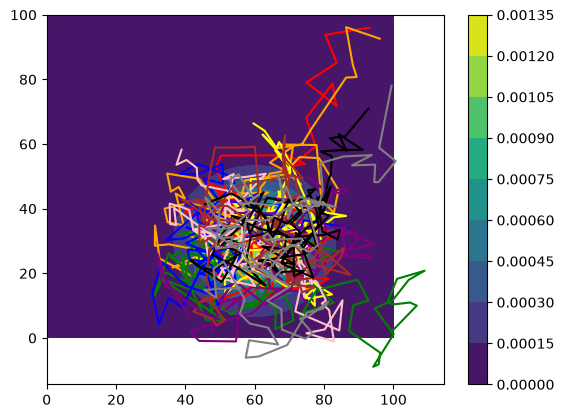

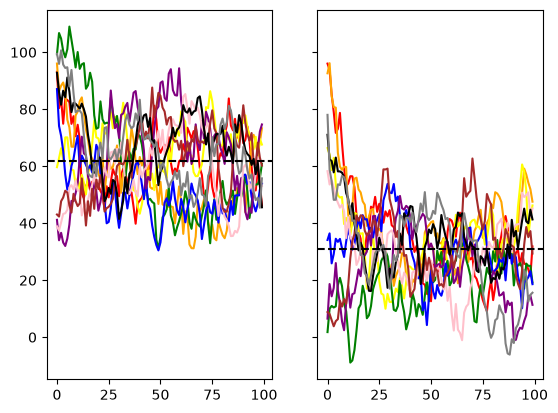

61.79840132219773 31.117251896361427


In [41]:
colors = [
    "red", "orange", "yellow", "green", "blue",
    "purple", "pink", "brown", "black", "grey",
]

mean = 80
sigma = 130
means = [randint(20,100),randint(20,100)]
means = [60,30]



Sigma = np.array([[sigma,0],
         [0,sigma]])

L = 1000 #leapfrog steps
dt = 0.5 #step size
M = np.array([[10000.0,0],
              [0,10000.0]])
print("the inverse mass matrix is:",np.linalg.inv(M))

p_start = np.random.normal(0,1)
p_start = np.random.default_rng().multivariate_normal([0,0], M, size=1)

#now computes alll chains at once
X0s = [[random()*100,random()*100] for i in range(10)]
Xns = np.array(dchain(np.array(X0s),100,dt,L,M,method="gaussian"))
print(Xns.shape)
for i in range(10):
    plt.plot(Xns[:,i,0],Xns[:,i,1],color=colors[i])


#Grid
x = np.linspace(0,100,100)
y = np.linspace(0,100,100)
X,Y = np.meshgrid(x,y)
pos = np.dstack((X,Y))

Z = multivariate_normal(means,Sigma).pdf(pos)



cf = plt.contourf(X,Y,Z,levels=10,cmap="viridis")
#plt.contour(X,Y,Z,levels=8,colors="white",linewidths = 0.5)
plt.colorbar(cf)
plt.show()


xspace = np.arange(100)
fig,ax = plt.subplots(1,2,sharey=True)
for i in range(10):
    ax[0].plot(xspace,Xns[:,i,0],color=colors[i])
    ax[1].plot(xspace,Xns[:,i,1],color=colors[i])

ax[0].axhline(np.mean(Xns[:,:,0]),color='black',ls='--')
ax[1].axhline(np.mean(Xns[:,:,1]),color='black',ls='--')
plt.show()
print(np.mean(Xns[:,:,0]),np.mean(Xns[:,:,1]))


Gaussian sampling
(10, 2)
(100, 10, 2)


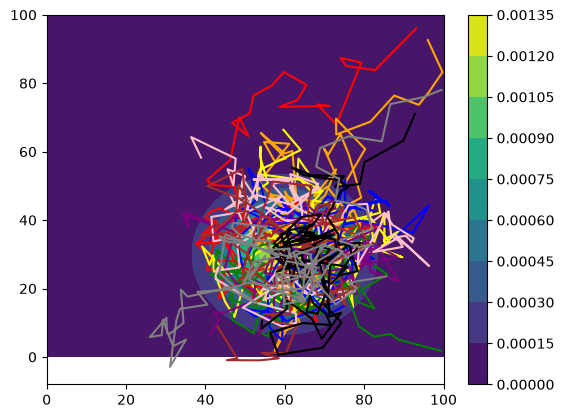

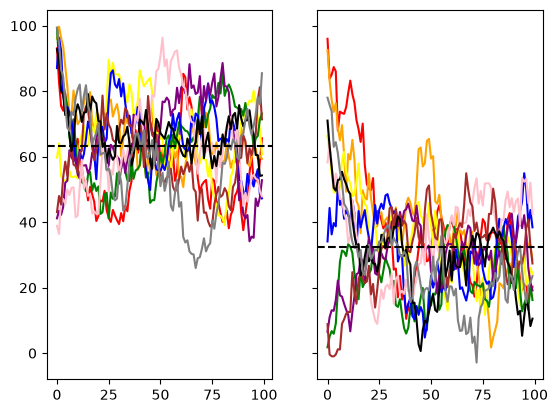

63.30061352492819 32.27569407456634


In [42]:
#NAIVE UTURN TEST

Xns = np.array(dchain(np.array(X0s),100,dt,L,M,method="gaussian"))
print(Xns.shape)
for i in range(10):
    plt.plot(Xns[:,i,0],Xns[:,i,1],color=colors[i])


#Grid
x = np.linspace(0,100,100)
y = np.linspace(0,100,100)
X,Y = np.meshgrid(x,y)
pos = np.dstack((X,Y))

Z = multivariate_normal(means,Sigma).pdf(pos)



cf = plt.contourf(X,Y,Z,levels=10,cmap="viridis")
#plt.contour(X,Y,Z,levels=8,colors="white",linewidths = 0.5)
plt.colorbar(cf)
plt.show()


xspace = np.arange(100)
fig,ax = plt.subplots(1,2,sharey=True)
for i in range(10):
    ax[0].plot(xspace,Xns[:,i,0],color=colors[i])
    ax[1].plot(xspace,Xns[:,i,1],color=colors[i])

ax[0].axhline(np.mean(Xns[:,:,0]),color='black',ls='--')
ax[1].axhline(np.mean(Xns[:,:,1]),color='black',ls='--')
plt.show()
print(np.mean(Xns[:,:,0]),np.mean(Xns[:,:,1]))


100%|██████████| 100/100 [00:00<00:00, 1381.89it/s]


chain shape: (100, 10, 2)


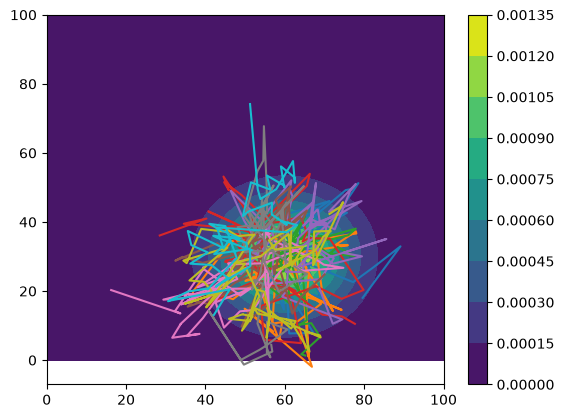

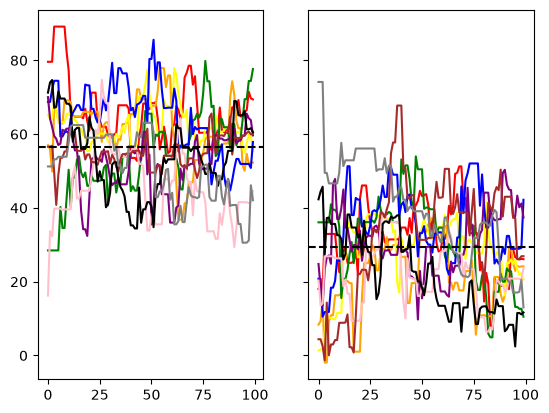

56.62553814215842 29.504167719283927


In [43]:
nsteps, nwalkers, ndim = 100, 10, 2
#burnin = nsteps // 5

X0s = [[random()*100,random()*100] for i in range(10)]
sampler = emcee.EnsembleSampler(nwalkers,ndim,log_gaussian,args=(means,Sigma))

sampler.run_mcmc(X0s,nsteps,progress=True)
Xns = sampler.get_chain()
print("chain shape:",Xns.shape)

for i in range(nwalkers):
    plt.plot(Xns[:,i,0],Xns[:,i,1])


#Grid
x = np.linspace(0,100,100)
y = np.linspace(0,100,100)
X,Y = np.meshgrid(x,y)
pos = np.dstack((X,Y))

Z = multivariate_normal(means,Sigma).pdf(pos)




cf = plt.contourf(X,Y,Z,levels=10,cmap="viridis")
#plt.contour(X,Y,Z,levels=8,colors="white",linewidths = 0.5)
plt.colorbar(cf)
plt.show()



xspace = np.arange(100)
fig,ax = plt.subplots(1,2,sharey=True)
for i in range(10):
    ax[0].plot(xspace,Xns[:,i,0],color=colors[i])
    ax[1].plot(xspace,Xns[:,i,1],color=colors[i])

ax[0].axhline(np.mean(Xns[:,:,0]),color='black',ls='--')
ax[1].axhline(np.mean(Xns[:,:,1]),color='black',ls='--')
plt.show()
print(np.mean(Xns[:,:,0]),np.mean(Xns[:,:,1]))


## Neal's Funnel:

100%|██████████| 100/100 [00:00<00:00, 2370.48it/s]

chain shape: (100, 10, 2)


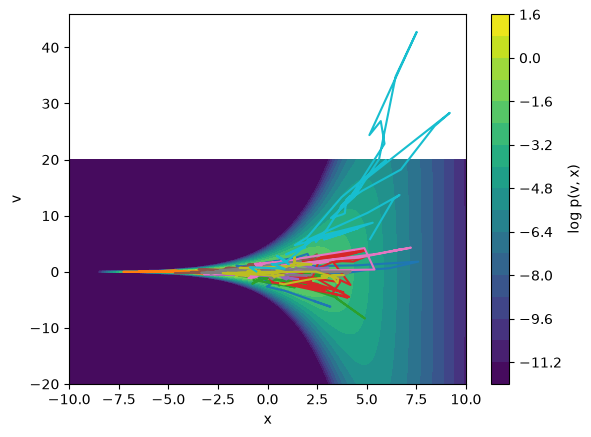

In [44]:
nsteps, nwalkers, ndim = 100, 10, 2
#burnin = nsteps // 5

X0s = rng.normal(size=(nwalkers,ndim))
sampler = emcee.EnsembleSampler(nwalkers,ndim,log_neal_funnel)

sampler.run_mcmc(X0s,nsteps,progress=True)
Xns = sampler.get_chain()
print("chain shape:",Xns.shape)

for i in range(nwalkers):
    plt.plot(Xns[:,i,0],Xns[:,i,1])

#plot neals funnel
x = np.linspace(-20, 20, 300)
v = np.linspace(-10, 10, 300)
X, V = np.meshgrid(x, v)          
pos = np.dstack((V, X))            

logp = log_neal_funnel(pos)        

cf = plt.contourf(V,X, np.maximum(logp, -12), levels=20, cmap="viridis")
plt.colorbar(cf, label="log p(v, x)")
plt.xlabel("x")
plt.ylabel("v")
plt.show()

100%|██████████| 100/100 [00:00<00:00, 2121.43it/s]


chain shape: (100, 10, 2)


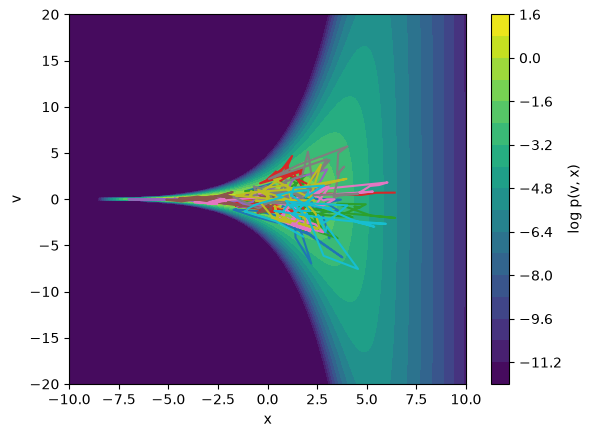

In [45]:
nsteps, nwalkers, ndim = 100, 10, 2
#burnin = nsteps // 5

X0s = rng.normal(size=(nwalkers,ndim))
sampler = emcee.EnsembleSampler(nwalkers,ndim,log_neal_funnel)

sampler.run_mcmc(X0s,nsteps,progress=True)
Xns = sampler.get_chain()
print("chain shape:",Xns.shape)

for i in range(nwalkers):
    plt.plot(Xns[:,i,0],Xns[:,i,1])

#plot neals funnel
x = np.linspace(-20, 20, 300)
v = np.linspace(-10, 10, 300)
X, V = np.meshgrid(x, v)          
pos = np.dstack((V, X))            

logp = log_neal_funnel(pos)        

cf = plt.contourf(V,X, np.maximum(logp, -12), levels=20, cmap="viridis")
plt.colorbar(cf, label="log p(v, x)")
plt.xlabel("x")
plt.ylabel("v")
plt.show()


## Marginal distributions comparison:

### Testing:

In [46]:
def leapfrog_gauss(x,p,dt,L,mass_matrix,grad_logp):
    ps = np.zeros((L+1))
    xs = np.zeros((L+1))
    
    for i in range(L):
        p_half = p-0.5 * dt * grad_logp(x)#np.gradient(potential_energy(xs[i]))
        x = x + dt / mass_matrix * p_half
        p = p_half - 0.5 * dt * grad_logp(x)
    return x,p

def dchain(x_0,N,dt,L,mass_matrix,method = "gaussian",random_seed = None, rho = 0):
    #getting method
    if method == "gaussian":
        print("Gaussian sampling")
        mu = 0
        d = x_0[0].size
        means = np.zeros(d)
        Sigma = np.zeros((d,d))
        for i in range(d):
            for j in range(d):
                means[i] = mu
                Sigma[i,j] = rho ** (np.abs(i-j))
        Sigma_inv = np.linalg.inv(Sigma)
        logp = lambda x: - 0.5 * (x - means).T @ Sigma_inv @ (x - means)
        grad_logp = lambda x: - Sigma_inv @ (x - means)
        leapfrog_used = leapfrog_gauss(grad_logp = grad_logp)
    elif method == "neal":
        print("Neal's funnel sampling")
        logp = log_neal_funnel
        is_log = True
        leapfrog_used = leapfrog_d
    else:
        print("invalid method")
        return "err"

    # getting/creating random state
    if random_seed == None:
        rng = np.random.default_rng()
    else:
        rng = np.random.default_rng(random_seed)
    #needs x_0 in shape (N_chains,d)

    X = np.zeros((N,len(x_0),len(x_0[0])))
    X[0] = x_0
    #print(x_0.shape)

    for n in range(N-1):
        p_0 = np.squeeze(rng.multivariate_normal(np.zeros(d), mass_matrix, size=len(x_0)))
        #print("p:",p_0)
        x_Ldt,p_Ldt = leapfrog_used(X[n],p_0,dt,L,mass_matrix,logp)
        al = alpha_d(X[n], x_Ldt, p_0, p_Ldt, mass_matrix,logp)
        accept = rng.random(len(al)) < al                # (20,) booleans
        X[n+1] = np.where(accept[:, None], x_Ldt, X[n])
        #print("Xn:",X[n],n)

    return X

def KL_div(hist, hist2, eps=1e-10):
    p = hist + eps
    q = hist2 + eps
    p = p / p.sum(axis=1, keepdims=True)   # normalize over bins, per dimension
    q = q / q.sum(axis=1, keepdims=True)
    return np.sum(p * np.log(p / q), axis=1)   # shape (d,)

def KL_comparison(Xns1,Xns2):
    # find shared histogram bins
    hi = np.max([np.max(Xns1),np.max(Xns2)])
    lo = np.min([np.min(Xns1),np.min(Xns2)])
    edges = np.linspace(lo, hi, nbins + 1)

    # create histogram form chain 1
    Xns_flat1 = Xns1.reshape(-1, Xns1.shape[-1])
    hist1 = []
    for i in range(Xns_flat1[0,:].size):
        histogram_data1, _ = np.histogram(Xns_flat1[:,i],bins = edges)
        hist1.append(histogram_data1)

    hist1 = np.asarray(hist1) # all bin entries for each dimension

    # create histogram from chain 2
    Xns_flat2 = Xns2.reshape(-1, Xns2.shape[-1])
    hist2 = []
    for i in range(Xns_flat2[0,:].size):
        histogram_data2, _ = np.histogram(Xns_flat2[:,i],bins = edges)
        hist2.append(histogram_data2)

    hist2 = np.asarray(hist2) # all bin entries for each dimension

    return KL_div(hist1,hist2), hist1, hist2


In [47]:
def leapfrog(x, p, dt, L, mass_inv, grad_logp):

    x = x.copy()
    p = p.copy()

    # Initial half-step
    p += 0.5 * dt * grad_logp(x)

    for i in range(L):

        # Full position step
        x += dt * (p @ mass_inv)

        # Full momentum step, except at the end
        if i != L - 1:
            p += dt * grad_logp(x)

    # Final half-step
    p += 0.5 * dt * grad_logp(x)

    return x, p

def dchain(x_0, N, dt, L, mass_matrix,
           method="gaussian", random_seed=None, rho=0):

    rng = np.random.default_rng(random_seed)

    nchains, d = x_0.shape

    if method == "gaussian":

        means = np.zeros(d)

        indices = np.arange(d)

        Sigma = rho ** np.abs(
            indices[:, None] - indices[None, :]
        )

        Sigma_inv = np.linalg.inv(Sigma)

        def logp(x):
            dx = x - means
            return -0.5 * np.sum(
                (dx @ Sigma_inv) * dx, axis=-1
            )

        def grad_logp(x):
            return -(x - means) @ Sigma_inv

    else:
        raise ValueError("Unsupported method")

    # Precompute mass matrix operations
    mass_inv = np.linalg.inv(mass_matrix)
    mass_chol = np.linalg.cholesky(mass_matrix)

    def kinetic_energy(p):
        return 0.5 * np.sum(
            (p @ mass_inv) * p, axis=-1
        )

    X = np.zeros((N, nchains, d))
    X[0] = x_0

    for n in range(N - 1):

        # Sample momentum
        p_0 = rng.standard_normal(
            (nchains, d)
        ) @ mass_chol.T

        # Leapfrog integration
        x_Ldt, p_Ldt = leapfrog(
            X[n], p_0, dt, L, mass_inv, grad_logp
        )

        # Hamiltonians
        H_old = -logp(X[n]) + kinetic_energy(p_0)
        H_new = -logp(x_Ldt) + kinetic_energy(p_Ldt)

        # Metropolis acceptance in log space
        log_alpha = np.minimum(0, H_old - H_new)

        accept = np.log(
            rng.random(nchains)
        ) < log_alpha

        X[n+1] = np.where(
            accept[:, None], x_Ldt, X[n]
        )

    return X

### 100D test

In [48]:
seed1 = 42
seed2 = 22
rng1 = np.random.default_rng(seed1)
rng2 = np.random.default_rng(seed2)

d = 100
nchains = 4
chain_length = 2500
step_size = 0.1
l_steps = 20
rho = 0
mass = 1

M = np.eye(d) * mass
means = np.zeros(d)
indices = np.arange(d)
Sigma = rho ** np.abs(indices[:, None] - indices[None, :])

# Chain 1
x0_1 = rng1.standard_normal((nchains,d))
X_HMC1 = dchain(x_0 = x0_1,
              N = 1000,
              dt = 0.1,
              L = l_steps,
              mass_matrix = M,
              random_seed = seed1,
              rho=0)

# Chain 2
x0_2 = rng2.standard_normal((nchains,d))
X_HMC2 = dchain(x_0 = x0_1,
              N = chain_length,
              dt = step_size,
              L = l_steps,
              mass_matrix = M,
              random_seed = seed2,
              rho=0)

print(KL_comparison(X_HMC1,X_HMC2)[0])

NameError: name 'nbins' is not defined

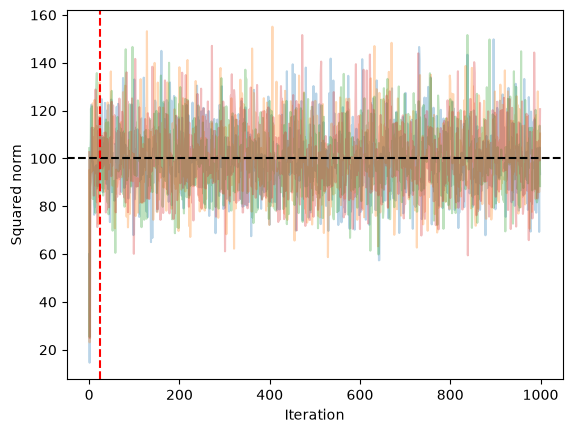

In [ ]:
r_squared = np.sum(X_HMC1**2, axis=-1)

burnin = 25
plt.plot(r_squared, alpha=0.3)
plt.axhline(100, color="black", linestyle="--")
plt.axvline(burnin, color="red", linestyle="--")

plt.xlabel("Iteration")
plt.ylabel("Squared norm")
plt.show()

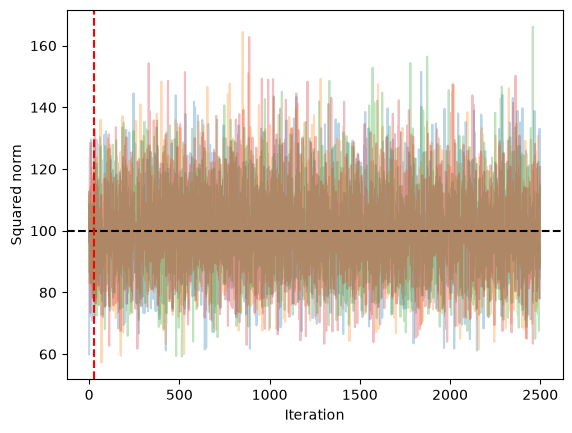

In [ ]:
r_squared = np.sum(X_HMC2**2, axis=-1)

burnin = 25
plt.plot(r_squared, alpha=0.3)
plt.axhline(100, color="black", linestyle="--")
plt.axvline(burnin, color="red", linestyle="--")

plt.xlabel("Iteration")
plt.ylabel("Squared norm")
plt.show()

In [ ]:
nwalkers, ndim = 2 * d, d
n_samples = 4000
nsteps = int(np.ceil(n_samples / nwalkers))

x0_3 = rng1.multivariate_normal(means,Sigma,size=nwalkers)
sampler = emcee.EnsembleSampler(nwalkers,ndim,log_gaussian,args=(means,Sigma))
sampler.run_mcmc(x0_3,nsteps,progress=True,skip_initial_state_check=True)
X_MC = sampler.get_chain()

100%|██████████| 20/20 [00:19<00:00,  1.01it/s]


(50, 200, 100)
50


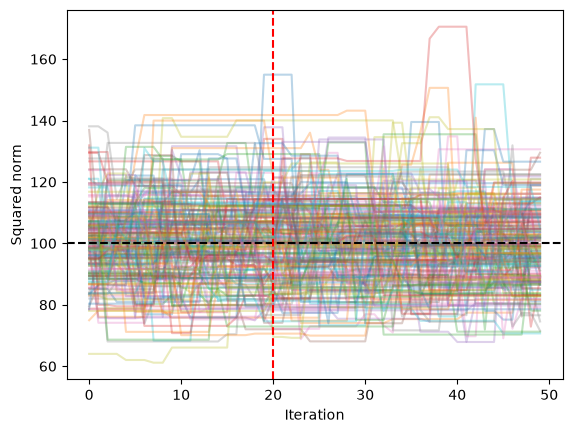

In [ ]:
r_squared = np.sum(X_MC**2, axis=-1)

burnin = 20
plt.plot(r_squared, alpha=0.3)
plt.axhline(100, color="black", linestyle="--")
plt.axvline(burnin, color="red", linestyle="--")

plt.xlabel("Iteration")
plt.ylabel("Squared norm")
plt.show()

In [ ]:
rng = np.random.default_rng(2)
d = 100
N_samples = 4000

X_true = rng.standard_normal((N_samples, d))
print(X_true.shape)
print(X_HMC1.shape)

(4000, 100)
(1000, 4, 100)


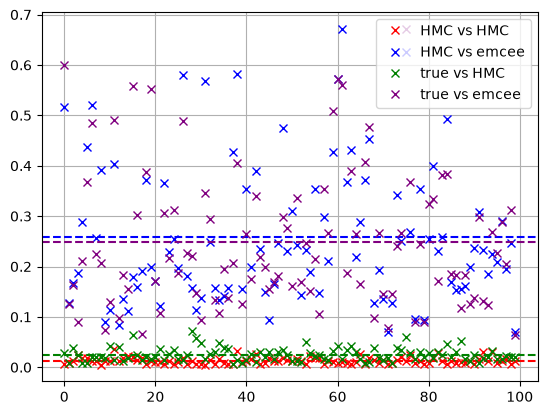

In [ ]:
hmc_comp = KL_comparison(X_HMC1,X_HMC2)[0]
mc_comp = KL_comparison(X_HMC1,X_MC)[0]
true_hmc = KL_comparison(X_true,X_HMC1)[0]
true_mc = KL_comparison(X_true,X_MC)[0]

plt.plot(hmc_comp,ls=' ',marker='x',label="HMC vs HMC",color='r')
plt.axhline(np.mean(hmc_comp),ls='--',color='r')
plt.plot(mc_comp,ls=' ',marker='x',label="HMC vs emcee",color='b')
plt.axhline(np.mean(mc_comp),ls='--',color='b')
plt.plot(true_hmc,ls=' ',marker='x',label="true vs HMC",color='g')
plt.axhline(np.mean(true_hmc),ls='--',color='g')
plt.plot(true_mc,ls=' ',marker='x',label="true vs emcee",color='purple')
plt.axhline(np.mean(true_mc),ls='--',color='purple')
plt.legend()
plt.grid()

### high-dimensionality

In [ ]:
from random import randint,random

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
import emcee

from benchmark_distr import sample_funnel, log_neal_funnel, log_gaussian
from HamiltonianSampler import leapfrog_d,alpha_d, gaussian_ND

In [ ]:
seed1 = 42
seed2 = 22
d = 100
means = np.zeros(d)
Sigma = np.eye(d)

L = 100 #leapfrog steps
nchains = 2
chain_length = 100
dt = 0.5 #step size
mass = 100
M = np.eye(d) * mass

nbins = 50

nwalkers = 2 * d + 1
nsteps = nchains * chain_length // nwalkers


(2, 100, 100)


TypeError: Gradient only defined for scalar-output functions. Output had shape: (2, 100).

In [ ]:
from scipy.stats import multivariate_normal

In [ ]:
#now computes all chains at once
X0s1 = [multivariate_normal.rvs(means,Sigma,1,random_state=seed1) for i in range(nchains)]
HMC1 = np.array(dchain(np.array(X0s1),chain_length,dt,L,M,method="gaussian",random_seed=seed1))

Gaussian sampling


KeyboardInterrupt: 

In [ ]:
X0s2 = [multivariate_normal.rvs(means,Sigma,1,random_state=seed2) for i in range(nchains)]
HMC2 = np.array(dchain(np.array(X0s2),chain_length,dt,L,M,method="gaussian",random_seed=seed2))

In [ ]:
rng = np.random.default_rng()
X0s1 = rng.multivariate_normal(means,Sigma,size=nchains)
sampler = emcee.EnsembleSampler(nchains,d,log_gaussian,args=(means,Sigma))
sampler.run_mcmc(X0s1,chain_length,progress=True,skip_initial_state_check=True)
MC = sampler.get_chain()

In [ ]:
hmc_comp = KL_comparison(HMC1,HMC2)[0]
mc_comp = KL_comparison(HMC1,MC)[0]

print(hmc_comp)
print(mc_comp)

plt.plot(hmc_comp,ls=' ',marker='x',label="HMC vs HMC",color='r')
plt.axhline(np.mean(hmc_comp),ls='--',color='r')
plt.plot(KL_comparison(HMC1,MC)[0],ls=' ',marker='x',label="HMC vs emcee",color='b')
plt.axhline(np.mean(mc_comp),ls='--',color='b')
plt.legend()
plt.grid()

### Graveyard:

In [ ]:
"""Xns_flat = Xns.reshape(-1, Xns.shape[-1])

print(Xns_flat.shape) # (600,6)

x = Xns_flat[:,0]
y = Xns_flat[:,1]

fig = plt.figure(figsize=(6, 6))
gs = fig.add_gridspec(2, 2, width_ratios=(4, 1), height_ratios=(1, 4),
                      hspace=0.05, wspace=0.05)

ax = fig.add_subplot(gs[1, 0])
ax_top = fig.add_subplot(gs[0, 0], sharex=ax)
ax_right = fig.add_subplot(gs[1, 1], sharey=ax)

ax.scatter(x, y, s=8, alpha=0.5)
ax_top.hist(x, bins=30)
ax_right.hist(y, bins=30, orientation="horizontal")

ax_top.tick_params(labelbottom=False)
ax_right.tick_params(labelleft=False)
ax.set_xlabel("x")
ax.set_ylabel("y")
plt.show()"""

'Xns_flat = Xns.reshape(-1, Xns.shape[-1])\n\nprint(Xns_flat.shape) # (600,6)\n\nx = Xns_flat[:,0]\ny = Xns_flat[:,1]\n\nfig = plt.figure(figsize=(6, 6))\ngs = fig.add_gridspec(2, 2, width_ratios=(4, 1), height_ratios=(1, 4),\n                      hspace=0.05, wspace=0.05)\n\nax = fig.add_subplot(gs[1, 0])\nax_top = fig.add_subplot(gs[0, 0], sharex=ax)\nax_right = fig.add_subplot(gs[1, 1], sharey=ax)\n\nax.scatter(x, y, s=8, alpha=0.5)\nax_top.hist(x, bins=30)\nax_right.hist(y, bins=30, orientation="horizontal")\n\nax_top.tick_params(labelbottom=False)\nax_right.tick_params(labelleft=False)\nax.set_xlabel("x")\nax.set_ylabel("y")\nplt.show()'

In [ ]:
"""Xns_flat = Xns.reshape(-1, Xns.shape[-1])   # (600, 6)
n = Xns_flat.shape[1]
labels = [f"p{i}" for i in range(n)]        # replace with your parameter names

fig, axes = plt.subplots(n, n, figsize=(2*n, 2*n), sharex="col")

for i in range(n):
    for j in range(n):
        ax = axes[i, j]
        if j > i:
            ax.axis("off")
            continue

        if i == j:
            ax.hist(Xns_flat[:, i], bins=30)
            ax.set_yticks([])
        else:
            ax.scatter(Xns_flat[:, j], Xns_flat[:, i], s=8, alpha=0.5)
            # share y within each row, except the diagonal panel
            if j > 0:
                ax.sharey(axes[i, 0])

        # tick labels only on the outer edge
        if i < n - 1:
            ax.tick_params(labelbottom=False)
        else:
            ax.set_xlabel(labels[j])
        if j > 0:
            ax.tick_params(labelleft=False)
        elif i > 0:
            ax.set_ylabel(labels[i])

fig.subplots_adjust(hspace=0.05, wspace=0.05)
plt.show()"""

'Xns_flat = Xns.reshape(-1, Xns.shape[-1])   # (600, 6)\nn = Xns_flat.shape[1]\nlabels = [f"p{i}" for i in range(n)]        # replace with your parameter names\n\nfig, axes = plt.subplots(n, n, figsize=(2*n, 2*n), sharex="col")\n\nfor i in range(n):\n    for j in range(n):\n        ax = axes[i, j]\n        if j > i:\n            ax.axis("off")\n            continue\n\n        if i == j:\n            ax.hist(Xns_flat[:, i], bins=30)\n            ax.set_yticks([])\n        else:\n            ax.scatter(Xns_flat[:, j], Xns_flat[:, i], s=8, alpha=0.5)\n            # share y within each row, except the diagonal panel\n            if j > 0:\n                ax.sharey(axes[i, 0])\n\n        # tick labels only on the outer edge\n        if i < n - 1:\n            ax.tick_params(labelbottom=False)\n        else:\n            ax.set_xlabel(labels[j])\n        if j > 0:\n            ax.tick_params(labelleft=False)\n        elif i > 0:\n            ax.set_ylabel(labels[i])\n\nfig.subplots_adjust(h

In [ ]:
"""import jax.numpy as jnp
from jax import grad,jit
import jax.random
from jax.scipy.stats import multivariate_normal


def sample_hmc(x0, log_pdf, n, L, epsilon, mass_matrix, key):

    mass_matrix_inv = jnp.linalg.inv(mass_matrix)

    # Define the potential and Hamiltonian
    def U(x):
        return -log_pdf(x)

    def H(x, p):
        return U(x) + 0.5 * p @ mass_matrix_inv @ p

    # Use JAX to get the gradient of U
    grad_x_U = grad(U)

    # The leap frog integrator. We speed this up using just-in-time compilation
    @jit
    def leap_frog(x, p):
        t = [x]
        for _ in range(L):
            p_prime = p - epsilon/2 * grad_x_U(x)
            x = x + epsilon * mass_matrix_inv @ p_prime
            p = p_prime - epsilon/2 * grad_x_U(x)
            t.append(x)
        return x, p, jnp.array(t)
    
    samples = [x0]
    trajectories = []
    n_accpeted = 0
    for _ in range(n):
        key, subkey = jax.random.split(key)
        # Sample a new momentum
        p0 = jax.random.multivariate_normal(
            subkey, mean=jnp.zeros_like(x0), cov=mass_matrix
        )
        # Integrate Hamiltonian dynamics
        x, p, t = leap_frog(x0, p0)

        # Metropolis-Hastings step
        a = min(1, jnp.exp(H(x0, p0) -  H(x, p)))

        key, subkey = jax.random.split(key)
        u = jax.random.uniform(subkey)
        if a >= u:
            x0 = x
            n_accpeted += 1
        
        samples.append(x0)
        trajectories.append(t)
    
    acceptance_rate = n_accpeted/n
    return jnp.array(samples), trajectories, acceptance_rate
"""

In [ ]:
"""key, subkey = jax.random.split(jax.random.PRNGKey(seed1))

X0s1 = [jax.random.multivariate_normal(key,means,Sigma,d) for i in range(nchains)]
print(jnp.array(X0s1).shape)
log_pdf = lambda x: multivariate_normal.logpdf(x, means, Sigma)
samples, trajectories, acceptance_rate = sample_hmc(
    x0=jnp.array(X0s1),
    log_pdf=log_pdf,
    n=chain_length,
    L=L, epsilon=dt, mass_matrix=M,
    key=subkey
)
print(samples.shape)"""